# Standard Deviation

![image.png](attachment:8f859bf1-4460-4032-9a27-28dceac32f70.png)

## Formulas

Population:  σ = √( Σ(xᵢ − μ)² / N )

Sample:      s = √( Σ(xᵢ − x̄)² / (n − 1) ) -> trying

Where:
- xᵢ = each value
- μ or x̄ = the mean
- N or n = number of values
- Σ = sum over all values

## Example

Data: 2, 4, 4, 4, 5, 5, 7, 9

1. Mean
   (2 + 4 + 4 + 4 + 5 + 5 + 7 + 9) / 8 = 40 / 8 = 5

2. Squared differences from the mean
   (2 − 5)² = 9
   (4 − 5)² = 1
   (4 − 5)² = 1
   (4 − 5)² = 1
   (5 − 5)² = 0
   (5 − 5)² = 0
   (7 − 5)² = 4
   (9 − 5)² = 16
   Sum = 32

3. Variance
   Population: 32 / 8 = 4
   Sample:     32 / 7 ≈ 4.57

4. Square root
   Population SD: √4    = 2
   Sample SD:     √4.57 ≈ 2.14

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.functional import cross_entropy
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()  # 32033
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [3]:
block_size = 3


def build_dateset(words):
    X, Y = [], []

    for w in words:
        # fill 3 letters in x fill next in y
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)  # 0.0.0 on first iteration
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

# first we want to shuffle the words
# then we want 80% training set
# then we want 10% dev test
# then we want 10% final test

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

train_data = words[:n1]
dev_data = words[n1:n2]
test_data = words[n2:]

Xtr, Ytr = build_dateset(train_data)
Xdev, Ydev = build_dateset(dev_data)
Xtest, Ytest = build_dateset(test_data)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


# How do we decide on 0.2
In the last notebook we manually placed 0.2 as multiplier. In big neuralnets no one is doing this manually.
So below we will explore how and why to calculate this.

weights * (gain/(fan_in**0.5))

gain table - pytorch doc: https://docs.pytorch.org/docs/2.14/nn.init.html
fan_in -> number of parameters

Basically we want to squash out the the growing variance by deviding on the fan_in and then compensate for the tanh squashing by multipliyng by the gain

In [4]:
# MLP revisited
n_embd = 10  # the dimensionality of the character embedding vectors
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),             generator=g)      # torch.Size([27, 10])
# W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 0.2    # torch.Size([30,200])
# proper way to set
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd*block_size)**0.5)  # torch.Size([30,200])
b1 = torch.randn(n_hidden,                        generator=g) * 0      # torch.Size([200])
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1  # torch.Size([200,27])
b2 = torch.randn(vocab_size,                      generator=g) * 0    # torch.Size([27,])

parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))  # 11897
for p in parameters:
    p.requires_grad = True

11897


The following thing is based on the following paper:

paper:https://arxiv.org/abs/1502.0185

pytorch doc: https://docs.pytorch.org/docs/2.14/nn.init.html

Basically they find that if the initialization is rightly done = the forward pass works good + the backward pass works good

x mean: tensor(0.0193)  x std: tensor(1.0092)
y mean: tensor(-0.0034)  y std: tensor(3.1505)


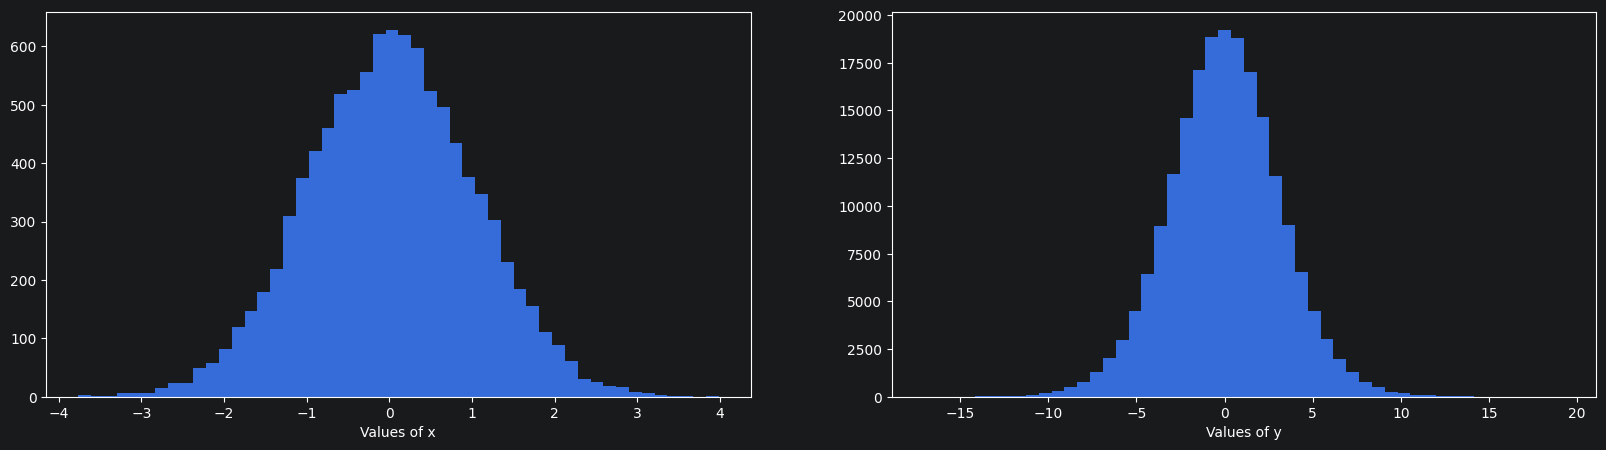

In [5]:
x = torch.randn(1000, 10)
# by uncommenting the multiplier we make y.std() = 1
w = torch.randn(10, 200) # / 10**0.5 # / sqroot of fan_in (the number of inputs)
y = x @ w

print("x mean:", x.mean(), " x std:",x.std())
print("y mean:", y.mean(), " y std:",y.std()) # how do we ensure this ends up 1?

plt.figure(figsize=(20,5))

plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50) # density is not probability!!!!!!!!
plt.xlabel("Values of x")
# plt.ylabel("Density")

plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50)
plt.xlabel("Values of y")
# plt.ylabel("Density")
plt.show()

In [26]:
 torch.randn(10000).sum()

tensor(-73.0525)

In [7]:
(torch.randn(100000)*0.3).std() # torch.randn -> makes std to 1 -> so whatever the multplier is that is the new standard deviation

# we want to set the standard deviation to
# std = gain / fan_in ** 0.5

tensor(0.2987)

In [8]:
# the preactivation = basically before the inputs go into the tanh we want to have gaussian destribution where the standard deviation is very close to 1

# as we can see the standard torch random gives us exactly this.
torch.randn(100000000).std() # the bigger the number - the closer the std is to 1

# to achieve this we basically apply a form of normalization to the preactivation results = h

tensor(1.0001)

In [9]:
# we want to make sure that the activations don't expand to infinity or go to zero
# so the right intialization of nn is very important


#in the paper mentioned he says that people analysed relu activation function and because of the squashing to zero in the negative space we have to start with weights that are guassian destribution with mean 0 and standard deviation is sqrt root 2/fenin

# this is described in https://arxiv.org/abs/1502.0185
# the batch norm is described here: https://arxiv.org/abs/1502.03167


# the whole point is that if we have right intialization of the forward pass the backward pass is rightly initilized too

# so karpathy point is that we want the preactivation to be neither too big and neither very close to zero, because when they are really close to zero the tanh basically does tanh(x) = x;


![image.png](attachment:febe4eee-05a6-4461-8053-2740fa3eb311.png)

In [10]:
max_steps = 200_000
batch_size = 32
lossi = []

for i in range(200_000):

    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    #forward pass
    emb = C[Xb]  # 32 samples of context of 3 letters each embedded in 10 numbers
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01 if i < 100_000 else 0.001
    for p in parameters:
        p.data += - lr * p.grad

    if i % 10_000 == 0:
        print(f'{i:7d} /{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    break;

      0 / 200000: 3.7863


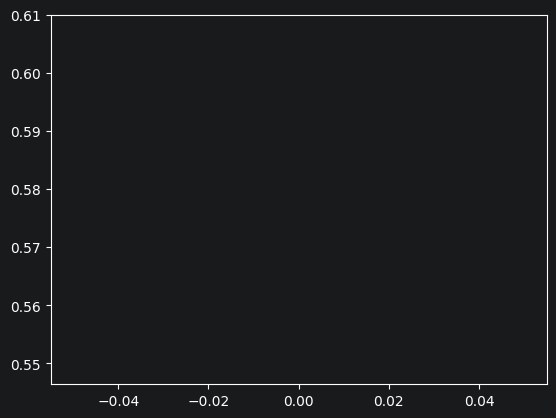

In [11]:
plt.plot(lossi)

In [12]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    # x, y = {'train': (Xtr, Ytr),
    #         'val': (Xdev, Ydev),
    #         'test': (Xtest, Ytest),
    #         }[split]

    if split == 'train':
        x, y = Xtr, Ytr
    elif split == 'val':
        x, y = Xdev, Ydev
    elif split == 'test':
        x, y = Xtest, Ytest

    emb = C[x] # (total entries, block_size, n_embd)
    embcat = emb.view(emb.shape[0],-1) # concat into (N, block_size)
    h = torch.tanh(embcat @ W1 + b1) # (N, vocab_size)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.6941800117492676
val 3.692779302597046


In [13]:
g = torch.Generator().manual_seed(2147483647+10)

for _ in range(20):
    out = []
    context = [0]*block_size #initialize with all ...

    while True:
        emb = C[torch.tensor([context])] # (1,block_size, n_embd)
        h = torch.tanh(emb.view(1,-1)@ W1 + b1 )
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples
        context = context[1:]+[ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out)) # decode and print the generated word


cbrpzvfqhojhmvifkjrrhxjthgjkhplfplkpjrkhubnfqposyhcpvgqhicoekouqpjcmmiirduxjeggpdzsmgpowsdqdijthx.
ouxwaljiqbq.
wqxtlojdiaryxixfkcgkpigslxjef.
gpoip.
gtlsfwysfwyoapaemoukjrksyadimqqosozswplojn.
waljifgeozkpfsadltuodnoebsrkoiyzkrynhgaojkchynrxwhkxqnoloqnpsbvbwde.
upvqmuitjgbvzmhpodgpycsislqhkkrnu.
zauznljyhxkbdvwtsdfttkzjmdtevl.
ky.
q.
cctooewaojktineojckicfcy.
zolndzse.
ku.
eoaigtkxerrqci.
kcfkyfbaxskktuglconwzysdhokhmlkfkkromcaddtxhvkoyadiwuwpxksxwymszxqpotzsik.
z.
rvgmknbflntixsfwdkkjmmy.
pvgkcvkhpvwbepodvkhhkxkbdttzscvnpgewjmjqfwjthgfwkewjdfxckxdytzvhgkpmytil.
hvqa.
gfckkjyoubgbiwddsesjrtzxecihknfzukhfgevzyylpoknfvtxxjkoikebez.
